# Several halos per snapshot read (TNG50-2)

The profile (`04_profile_one_halo_TNG50-2.ipynb`) showed that ~80% of the time of a halo is
reading the snapshot (349 GB, larger than the RAM) and selecting its particles, and the
core scan (`03_cores_scaling_TNG50-2.ipynb`) saturates at ~120 halos/h from N ≈ 16 workers.

The pipeline can now extract **K halos in one `Spectra` object** (`--halos_per_task K`,
one R200 per sightline in the fork), so the snapshot is read once per group.
The results are identical to K = 1 (`test_per_skewer_r200.py`, `test_halo_groups.py`).

Here the same **48 halos** are run with `W` workers × `K` halos per task (W × K = 48, so
every point is one round of tasks) and we compare the throughput (halos per hour).

In [1]:
import os
import sys
import json
import subprocess
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

%matplotlib widget
%load_ext autoreload
%autoreload 2

# Same plotting style as the other benchmark notebooks
plt.rc('font', family='serif', size=12)
plt.rcParams.update({
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.5,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
})

In [2]:
# ==============================================================================
# CELL 1: CONFIGURATION
# ==============================================================================
# Project root = the folder that contains tools/
PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())
BENCH_DIR = PROJ_ROOT / "benchmarks"

SIM_NAME  = "TNG50-2"
BASE_PATH = f"/home/STORAGE/{SIM_NAME}"
SNAP_NUM  = 25

# (workers, halos per task). (16, 1) is the old way at its best N (notebook 03).
# W x K = N_HALOS, so each point is a single round of tasks.
N_HALOS = 48
POINTS = [(16, 1), (16, 3), (8, 6), (4, 12), (2, 24)]

OMP = 1            # OpenMP threads per worker (no difference in notebook 03)

# Halos: one mass bin, as in notebook 03, so that every halo costs about the same
LOG_MASS_MIN, LOG_MASS_MAX = 11.0, 11.5
SEED = 42

# Reference numbers for the projections
N_HALOS_PRODUCTION = 637     # halos per realization
N_HALOS_ALL = 11081          # every TNG50-2 halo with log M200 >= 10
BEST_K1 = 122.4              # halos/h, best point of notebook 03 (N = 16, omp1)

RERUN = False      # False: reuse the .json files already in RESULTS_DIR

RESULTS_DIR = BENCH_DIR / "results" / f"{SIM_NAME}_halo_groups"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("results :", RESULTS_DIR)

results : /home/vroberto/FakeSpectra_DLAs/benchmarks/results/TNG50-2_halo_groups


## 1. Pick the halos

In [3]:
# ==============================================================================
# CELL 2: HALOS FROM ONE MASS BIN
# ==============================================================================
group_dir = Path(BASE_PATH) / f"groups_{SNAP_NUM:03d}"
group_files = sorted(group_dir.glob(f"fof_subhalo_tab_{SNAP_NUM:03d}.*.hdf5"),
                     key=lambda p: int(p.name.split(".")[-2]))   # numeric order = global index order

with h5py.File(group_files[0], "r") as f:
    hubble_h = float(f["Header"].attrs["HubbleParam"])

# Group_M_Crit200 of every FoF group, in Msun
mass = []
for gf in tqdm(group_files, desc="group files"):
    with h5py.File(gf, "r") as f:
        if "Group" in f and "Group_M_Crit200" in f["Group"]:
            mass.append(f["Group/Group_M_Crit200"][:])
log_mass = np.log10(np.maximum(np.concatenate(mass), 1e-10) * 1e10 / hubble_h)

# N_HALOS random halos in the bin, the same list for every point
in_bin = np.flatnonzero((log_mass >= LOG_MASS_MIN) & (log_mass < LOG_MASS_MAX))
rng = np.random.default_rng(SEED)
scan_ids = rng.choice(in_bin, size=N_HALOS, replace=False)

print(f"{len(in_bin)} halos in [{LOG_MASS_MIN}, {LOG_MASS_MAX}); "
      f"using {len(scan_ids)}")

group files: 100%|██████████| 128/128 [00:00<00:00, 1075.38it/s]

698 halos in [11.0, 11.5); using 48


## 2. Run the points
Each point is a fresh `python time_pipeline_workers.py ...`, roughly 10–30 min each.
Finished points are kept on disk, so the cell can be stopped and restarted.

In [4]:
# ==============================================================================
# CELL 3: RUN EVERY (workers, halos per task) POINT
# ==============================================================================
def run_point(n_workers, k, ids, out):
    # Run `ids` halos with `n_workers` processes and `k` halos per task; result in `out`.
    # Returns the wall time in minutes (None if the point was already on disk).
    if out.exists() and not RERUN:
        return None
    ids_file = out.with_suffix(".npy")
    np.save(ids_file, np.asarray(ids))
    cmd = [sys.executable, str(BENCH_DIR / "time_pipeline_workers.py"),
           "--sim", SIM_NAME, "--snap", str(SNAP_NUM), "--halo_ids", str(ids_file),
           "--n_workers", str(n_workers), "--omp_threads", str(OMP),
           "--halos_per_task", str(k), "--out", str(out)]
    # cwd = RESULTS_DIR: the pipeline module writes its error log in the cwd
    res = subprocess.run(cmd, capture_output=True, text=True, cwd=RESULTS_DIR)
    if res.returncode != 0:
        print(res.stderr[-3000:])
        raise RuntimeError(f"W={n_workers}, K={k} failed")
    return json.loads(res.stdout.splitlines()[-1])["wall"] / 60

bar = tqdm(POINTS, desc="scan")
for w, k in bar:
    bar.set_description(f"running W={w} K={k}")
    wall = run_point(w, k, scan_ids, RESULTS_DIR / f"W{w:02d}_K{k:02d}.json")
    bar.set_postfix(last=f"W={w} K={k}", wall="cached" if wall is None else f"{wall:.1f} min")
bar.close()

running W=2 K=24: 100%|██████████| 5/5 [1:14:00<00:00, 888.06s/it, last=W=2 K=24, wall=18.4 min] 


In [5]:
# ==============================================================================
# CELL 4: LOAD RESULTS
# ==============================================================================
rows = []
for f in sorted(RESULTS_DIR.glob("W*_K*.json")):
    d = json.loads(f.read_text())
    rows.append(dict(
        workers=d["n_workers"],
        halos_per_task=d["halos_per_task"],
        wall_min=d["wall"] / 60,
        halos_per_hour=d["n_halos"] / d["wall"] * 3600,      # throughput
        peak_mem_gb=d["peak_mem_gb"],
        failed=sum(h["status"] != "SUCCESS" for h in d["halos"]),
    ))
scan = pd.DataFrame(rows).sort_values(["halos_per_task", "workers"]).reset_index(drop=True)

# Gain over the best point of the old way, and projected wall times
scan["gain_vs_K1"] = scan["halos_per_hour"] / BEST_K1
scan[f"{N_HALOS_PRODUCTION}_halos_h"] = N_HALOS_PRODUCTION / scan["halos_per_hour"]
scan[f"{N_HALOS_ALL}_halos_h"] = N_HALOS_ALL / scan["halos_per_hour"]

assert scan["failed"].sum() == 0, "some halos failed: see the error log in RESULTS_DIR"
scan.round(2)

,workers,halos_per_task,wall_min,halos_per_hour,peak_mem_gb,failed,gain_vs_K1,637_halos_h,11081_halos_h
0,16,1,27.44,104.94,15.73,0,0.86,6.07,105.59
1,16,3,9.35,308.18,6.64,0,2.52,2.07,35.96
2,8,6,9.59,300.26,7.09,0,2.45,2.12,36.91
3,4,12,9.08,317.25,2.07,0,2.59,2.01,34.93
4,2,24,18.43,156.24,1.40,0,1.28,4.08,70.93


## 3. Results
(a) throughput of each point, with the best K = 1 point of notebook 03 as a dashed line;
(b) peak memory (the particle cache of a worker grows with K).

best: W = 4, K = 12  ->  317 halos/h (2.6x the old best), 2.0 h per realization, 34.9 h for all halos


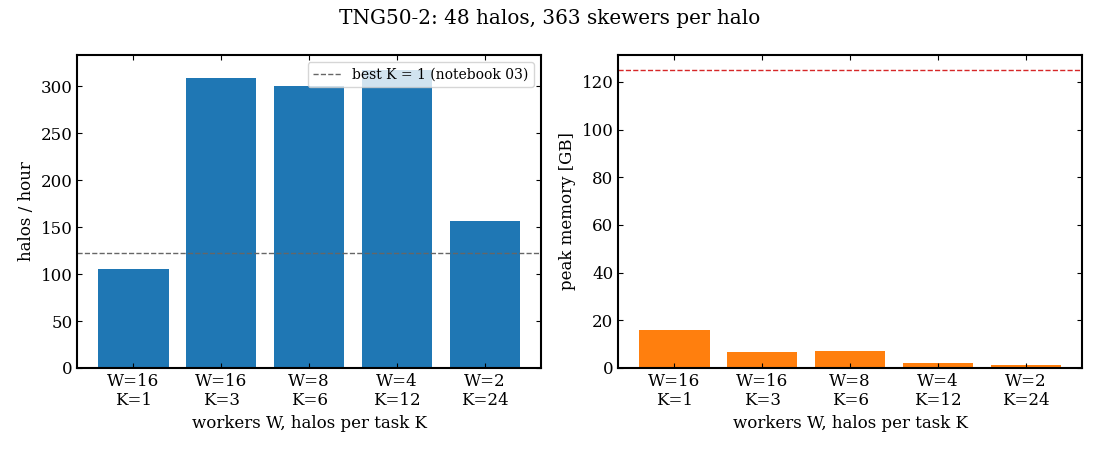

In [6]:
# ==============================================================================
# CELL 5: THROUGHPUT AND MEMORY
# ==============================================================================
labels = [f"W={w}\nK={k}" for w, k in zip(scan.workers, scan.halos_per_task)]
x = np.arange(len(scan))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].bar(x, scan.halos_per_hour, color="C0")
ax[0].axhline(BEST_K1, color="0.4", ls="--", lw=1, label="best K = 1 (notebook 03)")
ax[0].set_ylabel("halos / hour")
ax[0].legend(fontsize=10)

ax[1].bar(x, scan.peak_mem_gb, color="C1")
ax[1].axhline(125, color="C3", ls="--", lw=1)          # RAM of the machine
ax[1].set_ylabel("peak memory [GB]")

for a in ax:
    a.set_xticks(x, labels)
    a.set_xlabel("workers W, halos per task K")
fig.suptitle(f"{SIM_NAME}: {N_HALOS} halos, 363 skewers per halo")
fig.tight_layout()

best = scan.loc[scan.halos_per_hour.idxmax()]
print(f"best: W = {int(best.workers)}, K = {int(best.halos_per_task)}  ->  "
      f"{best.halos_per_hour:.0f} halos/h ({best.gain_vs_K1:.1f}x the old best), "
      f"{best[f'{N_HALOS_PRODUCTION}_halos_h']:.1f} h per realization, "
      f"{best[f'{N_HALOS_ALL}_halos_h']:.1f} h for all halos")